In [1]:

# Install required library
!pip install -q datasets

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from datasets import load_dataset

# Machine Learning libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Display settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 150)

print("ReelSentiment environment is ready!")

ReelSentiment environment is ready!


In [2]:

# Download IMDb movie review dataset
dataset = load_dataset("stanfordnlp/imdb")

# Convert training and testing data into DataFrames
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

# Display dataset information
print("IMDb Dataset Loaded Successfully!")

print("\nTraining records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining dataset:")
display(train_df.head())

print("\nTesting dataset:")
display(test_df.head())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

... (4 outputs left out)

IMDb Dataset Loaded Successfully!

Training records: 25000
Testing records: 25000

Training dataset:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also hear...,0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly b...",0
2,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might...,0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements...",0
4,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee song..<br /><br />""Is that all t...",0



Testing dataset:


,text,label
0,"I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and misunderstood. I tried to like ...",0
1,"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car chases, fights with the great Van...",0
2,its a totally average film with a few semi-alright action sequences that make the plot seem a little better and remind the viewer of the classic v...,0
3,STAR RATING: ***** Saturday Night **** Friday Night *** Friday Morning ** Sunday Night * Monday Morning <br /><br />Former New Orleans homicide co...,0
4,"First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may n...",0


In [3]:

print("Training Dataset Shape:")
print(train_df.shape)

print("\nColumn Information:")
print(train_df.info())

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nSentiment Distribution:")
print(train_df["label"].value_counts())

print("\nSample Movie Review:")
print(train_df["text"].iloc[0])

print("\nSample Sentiment:")
print(
    "Positive" if train_df["label"].iloc[0] == 1
    else "Negative"
)

Training Dataset Shape:
(25000, 2)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
None

Missing Values:
text     0
label    0
dtype: int64

Sentiment Distribution:
label
0    12500
1    12500
Name: count, dtype: int64

Sample Movie Review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants t

In [4]:

# Convert numeric labels into readable sentiment names
train_df["sentiment"] = train_df["label"].map({
    0: "Negative",
    1: "Positive"
})

# Calculate the number of words in each review
train_df["word_count"] = train_df["text"].apply(
    lambda review: len(review.split())
)

# Display important statistics
print("Sentiment Distribution:")
print(train_df["sentiment"].value_counts())

print("\nReview Length Statistics:")
print(train_df["word_count"].describe())

# Display sample reviews
display(train_df[["sentiment", "word_count", "text"]].head(5))

Sentiment Distribution:
sentiment
Negative    12500
Positive    12500
Name: count, dtype: int64

Review Length Statistics:
count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64


,sentiment,word_count,text
0,Negative,288,I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also hear...
1,Negative,214,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are because this film can hardly b..."
2,Negative,93,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no cogent story.<br /><br />One might...
3,Negative,118,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />The film has two strong elements..."
4,Negative,311,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee song..<br /><br />""Is that all t..."


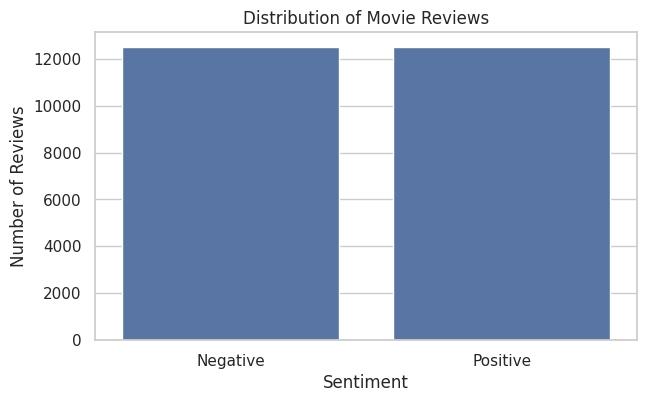

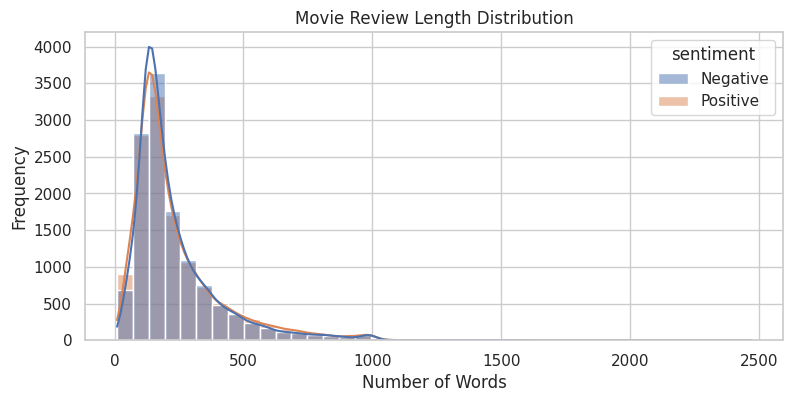

In [5]:


# Graph 1: Positive vs Negative reviews
plt.figure(figsize=(7, 4))

sns.countplot(
    data=train_df,
    x="sentiment"
)

plt.title("Distribution of Movie Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

# Graph 2: Review length distribution
plt.figure(figsize=(9, 4))

sns.histplot(
    data=train_df,
    x="word_count",
    hue="sentiment",
    bins=40,
    kde=True
)

plt.title("Movie Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [6]:

import re

def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Keep only letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning to training and testing data
train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Compare original and cleaned reviews
print("ORIGINAL REVIEW:")
print(train_df["text"].iloc[0][:500])

print("\nCLEANED REVIEW:")
print(train_df["clean_text"].iloc[0][:500])


ORIGINAL REVIEW:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

CLEANED REVIEW:
i rented i am curious yellow from my video store because of all the controversy that surrounded it when it was first released in i also heard that at first it was seized by u s customs if it ever tried to enter this country therefore being a fan of films considered controversial i really had to see this for myself the plot is centered around a young swedish drama student named lena who wants to learn everything she can about life in particular she wants to focu

In [7]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn vocabulary from training data only
X_train = tfidf.fit_transform(train_df["clean_text"])

# Transform test data using the same vocabulary
X_test = tfidf.transform(test_df["clean_text"])

# Target labels
y_train = train_df["label"]
y_test = test_df["label"]

print("TF-IDF conversion completed!")
print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Number of vocabulary features:", len(tfidf.vocabulary_))


TF-IDF conversion completed!
Training feature matrix: (25000, 20000)
Testing feature matrix: (25000, 20000)
Number of vocabulary features: 20000


In [9]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Model Accuracy:", round(baseline_accuracy * 100, 2), "%")


Baseline Model Accuracy: 50.0 %


In [10]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    C=2,
    random_state=42
)

model.fit(X_train, y_train)

print("ReelSentiment model training completed!")


ReelSentiment model training completed!


In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions)
recall = recall_score(y_test, predictions)
f1 = f1_score(y_test, predictions)

print("REELSENTIMENT MODEL PERFORMANCE")
print("--------------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Negative", "Positive"]
))


REELSENTIMENT MODEL PERFORMANCE
--------------------------------
Accuracy : 90.1 %
Precision: 0.8985
Recall   : 0.9042
F1 Score : 0.9014

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



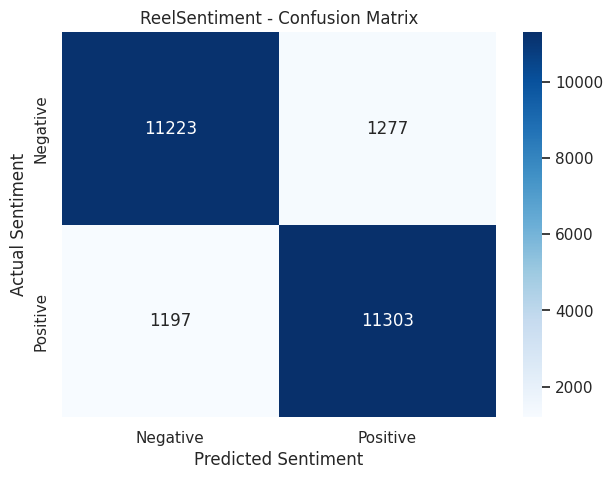

Confusion Matrix:
[[11223  1277]
 [ 1197 11303]]


In [12]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("ReelSentiment - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

print("Confusion Matrix:")
print(cm)


In [13]:

import pandas as pd
import numpy as np

# Get vocabulary and model coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = model.coef_[0]

word_importance = pd.DataFrame({
    "word": feature_names,
    "importance": coefficients
})

# Strongest positive words
positive_words = word_importance.sort_values(
    by="importance",
    ascending=False
).head(15)

# Strongest negative words
negative_words = word_importance.sort_values(
    by="importance",
    ascending=True
).head(15)

print("TOP POSITIVE WORDS")
display(positive_words)

print("TOP NEGATIVE WORDS")
display(negative_words)


TOP POSITIVE WORDS


,word,importance
6628,great,7.945652
5179,excellent,6.688761
12349,perfect,5.651095
19602,wonderful,5.271854
555,amazing,4.651446
15929,the best,4.365500
17822,today,4.341308
2169,best,4.268201
6194,fun,4.193142
15348,superb,3.907206


TOP NEGATIVE WORDS


,word,importance
1784,bad,-8.647492
19693,worst,-8.481270
1741,awful,-7.355417
2382,boring,-6.559522
16847,the worst,-6.545273
12649,poor,-6.068722
18836,waste,-6.003606
15613,terrible,-5.301491
12653,poorly,-4.984507
19689,worse,-4.981850


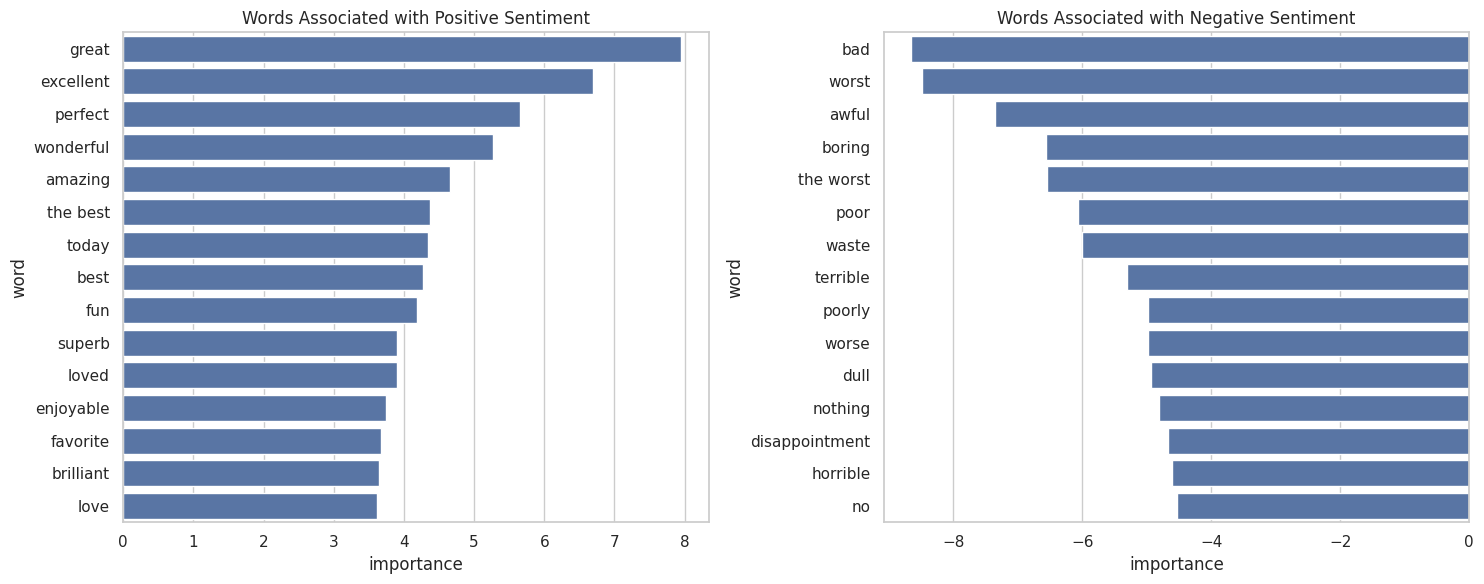

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=positive_words,
    x="importance",
    y="word",
    ax=axes[0]
)
axes[0].set_title("Words Associated with Positive Sentiment")

sns.barplot(
    data=negative_words,
    x="importance",
    y="word",
    ax=axes[1]
)
axes[1].set_title("Words Associated with Negative Sentiment")

plt.tight_layout()
plt.show()


In [15]:

def predict_sentiment(review):
    cleaned_review = clean_text(review)

    review_vector = tfidf.transform([cleaned_review])

    prediction = model.predict(review_vector)[0]

    probability = model.predict_proba(review_vector)[0]

    sentiment = "Positive" if prediction == 1 else "Negative"

    confidence = probability[prediction] * 100

    print("\nREELSENTIMENT PREDICTION")
    print("-----------------------")
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Model Confidence:", round(confidence, 2), "%")


# Try your own review
predict_sentiment(
    "This movie was absolutely fantastic. The acting and story were brilliant!"
)



REELSENTIMENT PREDICTION
-----------------------
Review: This movie was absolutely fantastic. The acting and story were brilliant!
Predicted Sentiment: Positive
Model Confidence: 83.4 %


In [16]:
predict_sentiment(
    "The movie was boring, poorly written and a complete waste of time."
)


REELSENTIMENT PREDICTION
-----------------------
Review: The movie was boring, poorly written and a complete waste of time.
Predicted Sentiment: Negative
Model Confidence: 99.77 %


In [17]:

import os

os.makedirs("outputs", exist_ok=True)

# Save classification report
report = classification_report(
    y_test,
    predictions,
    target_names=["Negative", "Positive"],
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "outputs/classification_report.csv"
)

# Save confusion matrix
pd.DataFrame(
    cm,
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
).to_csv("outputs/confusion_matrix.csv")

# Save word importance
word_importance.sort_values(
    by="importance",
    ascending=False
).to_csv("outputs/word_importance.csv", index=False)

# Save model comparison
comparison = pd.DataFrame({
    "Model": ["Dummy Classifier", "Logistic Regression"],
    "Accuracy": [baseline_accuracy, accuracy],
    "F1 Score": [
        f1_score(y_test, baseline_predictions),
        f1
    ]
})

comparison.to_csv("outputs/model_comparison.csv", index=False)

print("All evaluation files saved successfully!")


All evaluation files saved successfully!


In [18]:

import joblib

joblib.dump(tfidf, "tfidf_vectorizer.pkl")
joblib.dump(model, "reelsentiment_model.pkl")

print("Model and TF-IDF vectorizer saved successfully!")


Model and TF-IDF vectorizer saved successfully!


In [19]:

import os
import zipfile

# Create project folders
os.makedirs("outputs", exist_ok=True)

# Create requirements file
requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
datasets
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

# Create GitHub ignore file
gitignore = """__pycache__/
.ipynb_checkpoints/
.venv/
env/
*.pyc
"""

with open(".gitignore", "w") as f:
    f.write(gitignore)

# Package model and output files
files_to_package = [
    "tfidf_vectorizer.pkl",
    "reelsentiment_model.pkl",
    "requirements.txt",
    ".gitignore",
    "outputs/classification_report.csv",
    "outputs/confusion_matrix.csv",
    "outputs/word_importance.csv",
    "outputs/model_comparison.csv"
]

with zipfile.ZipFile(
    "ReelSentiment_GitHub_Files.zip", "w"
) as zip_file:
    for file in files_to_package:
        if os.path.exists(file):
            zip_file.write(file)

print("GitHub files prepared successfully!")


GitHub files prepared successfully!
